
<font size=6>Artificial Intelligence and Machine Learning : </font>
<font size=6>SuperKart Model Deployment</font>

# Problem Statement

## Business Context

A sales forecast predicts future sales revenue based on historical data, industry trends, and the status of the current sales pipeline. Businesses use the sales forecast to estimate weekly, monthly, quarterly, and annual sales totals. A company needs to make an accurate sales forecast as it adds value across an organization and helps the different verticals to chalk out their future course of action.

Forecasting helps an organization plan its sales operations by region and provides valuable insights to the supply chain team regarding the procurement of goods and materials. An accurate sales forecast process has many benefits, which include improved decision-making about the future and the reduction of sales pipeline and forecast risks. Moreover, it helps to reduce the time spent in planning territory coverage and establishes benchmarks that can be used to assess trends in the future.

## Objective

SuperKart is a retail chain operating supermarkets and food marts across various tier cities, offering a wide range of products. To optimize its inventory management and make informed decisions around regional sales strategies, SuperKart wants to accurately forecast the sales revenue of its outlets for the upcoming quarter.

To operationalize these insights at scale, the company has partnered with a data science firm, not just to build a predictive model based on historical sales data but also to develop and deploy a robust forecasting solution that can be integrated into SuperKart’s decision-making systems and used across its network of stores.

## Data Dictionary

The data contains the different attributes of the various products and stores.

- **Product_Id**: Unique identifier of each product, each identifier having two letters at the beginning, followed by a number  
- **Product_Weight**: Weight of each product  
- **Product_Sugar_Content**: Sugar content of each product, like low sugar, regular, and no sugar  
- **Product_Allocated_Area**: Ratio of the allocated display area of each product to the total display area of all the products in a store  
- **Product_Type**: Broad category for each product like meat, snack foods, hard drinks, dairy, canned, soft drinks, health and hygiene, baking goods, bread, breakfast, frozen foods, fruits and vegetables, household, seafood, starchy foods, others  
- **Product_MRP**: Maximum retail price of each product  
- **Store_Id**: Unique identifier of each store  
- **Store_Establishment_Year**: Year in which the store was established  
- **Store_Size**: Size of the store, depending on sq. feet, like high, medium, and low  
- **Store_Location_City_Type**: Type of city in which the store is located, like Tier 1, Tier 2, and Tier 3. Tier 1 consists of cities where the standard of living is comparatively higher than that of its Tier 2 and Tier 3 counterparts  
- **Store_Type**: Type of store depending on the products that are being sold there, like Departmental Store, Supermarket Type 1, Supermarket Type 2, and Food Mart  
- **Product_Store_Sales_Total**: Total revenue generated by the sale of that particular product in that particular store  

# Installing and Importing Necessary Libraries

In [1]:
# Installing the libraries with the specified version.
!pip install pandas==2.2.2 numpy==2.0.2 scikit-learn==1.6.1 xgboost==2.1.4 joblib==1.4.2 streamlit==1.43.2 huggingface_hub==0.29.3 -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 223.6/223.6 MB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 301.8/301.8 kB 27.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 87.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 469.0/469.0 kB 42.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.5/65.5 kB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 116.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 5.50.0 requires huggingface-hub<2.0,>=0.33.5, but you have huggingface-hub 0.29.3 which is incompatible.
transformers 5.0.0 requires huggingface-hub<2.0,>=1.3.0, but you have huggingface-hub 0.29.3 which is incompatible.
diffusers 0.37.1 requires huggingface-hub<2.0,>=0.34.0, but you have huggingface-hub 0.29.3 which is incompatible.


**Note:**

- After running the above cell, kindly restart the notebook kernel (for Jupyter Notebook) or runtime (for Google Colab) and run all cells sequentially from the next cell.

- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in this notebook.

In [2]:
# for data manipulation
import pandas as pd
import numpy as np

import sklearn
import xgboost
import matplotlib.pyplot as plt
import seaborn as sns

# for data preprocessing and pipeline creation
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn import metrics
from sklearn.pipeline import Pipeline # Import Pipeline

# for model training, tuning, and evaluation (regression metrics)
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

# for model serialization
import joblib

# for creating a folder
import os

# for Hugging Face Space authentication to upload files
from huggingface_hub import login, HfApi

In [3]:
# Set scikit-learn's display mode to 'diagram' for better visualization of pipelines and estimators
sklearn.set_config(display='diagram')

# Loading the Dataset

In [4]:
# uncomment and run the below code snippets if the dataset is present in the Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
# Load the dataset from a CSV file into a Pandas DataFrame
data = pd.read_csv('/content/drive/MyDrive/SuperKart.csv',low_memory=False)

In [6]:
# Create a copy of the dataframe
dataset = data.copy()

# Data Overview

In [ ]:
# checking shape of the data
print(f"There are {dataset.shape[0]} rows and {dataset.shape[1]} columns.")

There are 8763 rows and 12 columns.


In [ ]:
# Display the first five rows of the dataset
dataset.head()

,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total
0,FD6114,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,2009,Medium,Tier 2,Supermarket Type2,2842.40
1,FD7839,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,1999,Medium,Tier 1,Departmental Store,4830.02
2,FD5075,14.28,Regular,0.031,Canned,162.08,OUT001,1987,High,Tier 2,Supermarket Type1,4130.16
3,FD8233,12.10,Low Sugar,0.112,Baking Goods,186.31,OUT001,1987,High,Tier 2,Supermarket Type1,4132.18
4,NC1180,9.57,No Sugar,0.010,Health and Hygiene,123.67,OUT002,1998,Small,Tier 3,Food Mart,2279.36


In [ ]:
# Display the column names of the dataset
dataset.columns

Index(['Product_Id', 'Product_Weight', 'Product_Sugar_Content',
       'Product_Allocated_Area', 'Product_Type', 'Product_MRP', 'Store_Id',
       'Store_Establishment_Year', 'Store_Size', 'Store_Location_City_Type',
       'Store_Type', 'Product_Store_Sales_Total'],
      dtype='object')

In [ ]:
# checking column datatypes and number of non-null values
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8763 entries, 0 to 8762
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Product_Id                 8763 non-null   object 
 1   Product_Weight             8763 non-null   float64
 2   Product_Sugar_Content      8763 non-null   object 
 3   Product_Allocated_Area     8763 non-null   float64
 4   Product_Type               8763 non-null   object 
 5   Product_MRP                8763 non-null   float64
 6   Store_Id                   8763 non-null   object 
 7   Store_Establishment_Year   8763 non-null   int64  
 8   Store_Size                 8763 non-null   object 
 9   Store_Location_City_Type   8763 non-null   object 
 10  Store_Type                 8763 non-null   object 
 11  Product_Store_Sales_Total  8763 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 821.7+ KB


**Observations**

- *Product_Sugar_Content*, *Product_Type*, *Store_Id*, *Store_Size*, *Store_Location_City_Type* and *Store_Type* are categorical-type variables.
- All other variables are numerical in nature.

In [ ]:
# checking for duplicate values
dataset.duplicated().sum()

np.int64(0)

- There are no duplicate values in the data.

In [ ]:
# checking for missing values
dataset.isnull().sum()

,0
Product_Id,0
Product_Weight,0
Product_Sugar_Content,0
Product_Allocated_Area,0
Product_Type,0
Product_MRP,0
Store_Id,0
Store_Establishment_Year,0
Store_Size,0
Store_Location_City_Type,0


- There are no missing values in both numerical and categorical columns.

# Exploratory Data Analysis

Let's start by defining the target and predictor (numerical and categorical) variables.

- We'll not consider the `Product_Id` attribute as it serves only as a unique identifier and does not add value to the analysis and modeling.

In [8]:
# Define the target variable for the regression task
target = 'Product_Store_Sales_Total'
numeric_features = [
    'Product_Weight',          # Weight of each product
    'Product_Allocated_Area',  # Ratio of the allocated display area of each product to the total display area of all the products in a store
    'Product_MRP',             # Maximum retail price of each product
    'Store_Establishment_Year' # Year in which the store was established
]
# List of categorical features in the dataset
categorical_features = [
    'Product_Sugar_Content',  # Sugar content of each product, like low sugar, regular, and no sugar
    'Product_Type',        #  Broad category for each product like meat, snack foods, hard drinks, dairy, canned, soft drinks, health and hygiene, baking goods, bread, breakfast, frozen foods, fruits and vegetables, household, seafood, starchy foods, others
    'Store_Id',           # Unique identifier of each store
    'Store_Size',     # Size of the store, depending on sq. feet, like high, medium, and low
    'Store_Location_City_Type',# Type of city in which the store is located, like Tier 1, Tier 2, and Tier 3
    'Store_Type'  # Type of store depending on the products that are being sold there, like Departmental Store, Supermarket Type 1, Supermarket Type 2, and Food Mart
]

## Univariate Analysis

In [ ]:
# Generate summary statistics for numerical features
dataset[numeric_features].describe()

,Product_Weight,Product_Allocated_Area,Product_MRP,Store_Establishment_Year
count,8763.000000,8763.000000,8763.000000,8763.000000
mean,12.653792,0.068786,147.032539,2002.032751
std,2.217320,0.048204,30.694110,8.388381
min,4.000000,0.004000,31.000000,1987.000000
25%,11.150000,0.031000,126.160000,1998.000000
50%,12.660000,0.056000,146.740000,2009.000000
75%,14.180000,0.096000,167.585000,2009.000000
max,22.000000,0.298000,266.000000,2009.000000


1. **Product Weight :**
Most products have a weight between **11 and 14 units**, indicating that the inventory is concentrated around moderately sized items. However, the presence of products as light as **4 units** and as heavy as **22 units** shows a reasonable variation, suggesting a mix of lightweight and bulky goods.

2. **Product Allocated Area :**
The majority of products occupy a relatively small display space, typically between **0.03 and 0.09** of the total area. However, some products take up a significantly larger share (up to **0.298**), indicating that certain items are given high visibility or priority in store layouts.

3. **Product MRP :**
Most products are priced in the range of **₹126 to ₹167**, showing a concentration around mid-range pricing. The wide spread from **₹31 to ₹266** suggests a diverse pricing strategy, covering both budget-friendly and premium products.

4. **Store Establishment Year :**
Most stores were established between **1998 and 2009**, with a median around **2009**, indicating that a large portion of stores are relatively newer. However, the presence of older stores dating back to **1987** suggests a mix of legacy and recently established outlets.

**Overall Insight :**
The dataset reflects a **balanced mix of product sizes, pricing, and store maturity**, with slight skewness toward newer stores and mid-range products. The variability in allocated area and pricing indicates strategic merchandising and segmentation across stores.

In [ ]:
# Generate summary statistics for categorical features
dataset[categorical_features].describe()

,Product_Sugar_Content,Product_Type,Store_Id,Store_Size,Store_Location_City_Type,Store_Type
count,8763,8763,8763,8763,8763,8763
unique,4,16,4,3,3,4
top,Low Sugar,Fruits and Vegetables,OUT004,Medium,Tier 2,Supermarket Type2
freq,4885,1249,4676,6025,6262,4676


1. **Product Sugar Content :**
The dataset contains **4 unique categories**, with **"Low Sugar"** being the most dominant (4885 occurrences). This indicates a strong skew toward healthier or low-sugar products, suggesting consumer preference or strategic product placement.

2. **Product Type :**
There are **16 different product categories**, showing a diverse product portfolio. Among them, **"Fruits and Vegetables"** is the most frequent (1249 occurrences), indicating high demand or frequent stocking of fresh produce.

3. **Store Id :**
There are only **4 unique stores**, with **"OUT004"** contributing the highest number of records (4676). This suggests that the dataset is somewhat imbalanced across stores, with one store contributing a significant portion of the data.

4. **Store Size :**
The dataset includes **3 store sizes** (Low, Medium, High), with **"Medium"** being the most common (6025 occurrences). This implies that most operations and sales data are coming from mid-sized stores.

5. **Store Location City Type :**
There are **3 city tiers**, with **"Tier 2"** cities dominating (6262 occurrences). This suggests that the business has a stronger presence or higher activity in mid-tier cities compared to Tier 1 and Tier 3.

6. **Store Type :**
There are **4 store types**, with **"Supermarket Type2"** being the most frequent (4676 occurrences). This indicates that this store format is likely the primary revenue driver or most widely deployed format.

**Overall Insight :**
The categorical data shows clear **dominance patterns** across multiple features (Low Sugar products, Fruits & Vegetables, Tier 2 cities, Medium stores, and Supermarket Type2). This indicates potential **data imbalance**, which should be carefully handled during modeling to avoid biased predictions.

In [ ]:
# Let's check the unique values for categorical variables

# list of all categorical variables
cat_col = dataset.select_dtypes(include="object").columns.tolist()

# printing the number of occurrences of each unique value in each categorical column
for column in cat_col:
    print(dataset[column].value_counts(normalize=True))
    print("-" * 50)

Product_Id
FD306     0.000114
FD6114    0.000114
FD7839    0.000114
FD5075    0.000114
FD8233    0.000114
            ...   
FD1387    0.000114
FD1231    0.000114
FD5276    0.000114
FD8553    0.000114
FD6027    0.000114
Name: proportion, Length: 8763, dtype: float64
--------------------------------------------------
Product_Sugar_Content
Low Sugar    0.557457
Regular      0.256875
No Sugar     0.173342
reg          0.012325
Name: proportion, dtype: float64
--------------------------------------------------
Product_Type
Fruits and Vegetables    0.142531
Snack Foods              0.131119
Frozen Foods             0.092548
Dairy                    0.090836
Household                0.084446
Baking Goods             0.081707
Canned                   0.077257
Health and Hygiene       0.071665
Meat                     0.070524
Soft Drinks              0.059226
Breads                   0.022823
Hard Drinks              0.021226
Others                   0.017232
Starchy Foods            0.016090

**Observations**


- Product_Id has **8763 distinct categories**, where each product appears only once (very low proportion ~0.000114), indicating it is a unique identifier and not useful as a direct predictive feature.

- Product_Sugar_Content has **4 categories**, wherein **'Low Sugar'** is the most common, followed by 'Regular' and 'No Sugar'. There is also a small inconsistent category **'reg'**, which may require data cleaning.

- Product_Type has **16 categories**, wherein **'Fruits and Vegetables'** is the most common, followed closely by 'Snack Foods' and 'Frozen Foods', indicating higher representation of daily-consumption items.

- Store_Id has **4 categories**, wherein **'OUT004'** dominates the dataset, contributing more than half of the observations, suggesting data imbalance across stores.

- Store_Size has **3 categories**, wherein **'Medium'** stores are the most common, indicating that most sales data comes from mid-sized stores.

- Store_Location_City_Type has **3 categories**, wherein **'Tier 2'** cities dominate, showing that the business is more concentrated in mid-tier cities.

- Store_Type has **4 categories**, wherein **'Supermarket Type2'** is the most common store format, contributing the largest share of data.

In [ ]:
# Generate summary statistics for the target variable
dataset[target].describe()

,Product_Store_Sales_Total
count,8763.000000
mean,3464.003640
std,1065.630494
min,33.000000
25%,2761.715000
50%,3452.340000
75%,4145.165000
max,8000.000000


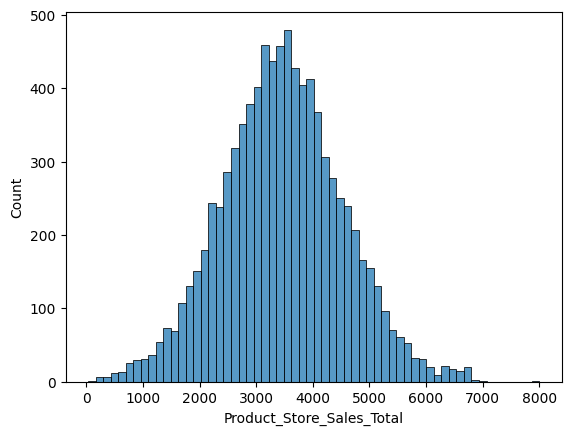

In [ ]:
# Check the distribution of the target variable
sns.histplot(dataset[target]);

**Observations**

- *Product_Store_Sales_Total* appears to be normally distributed.

## Bivariate Analysis

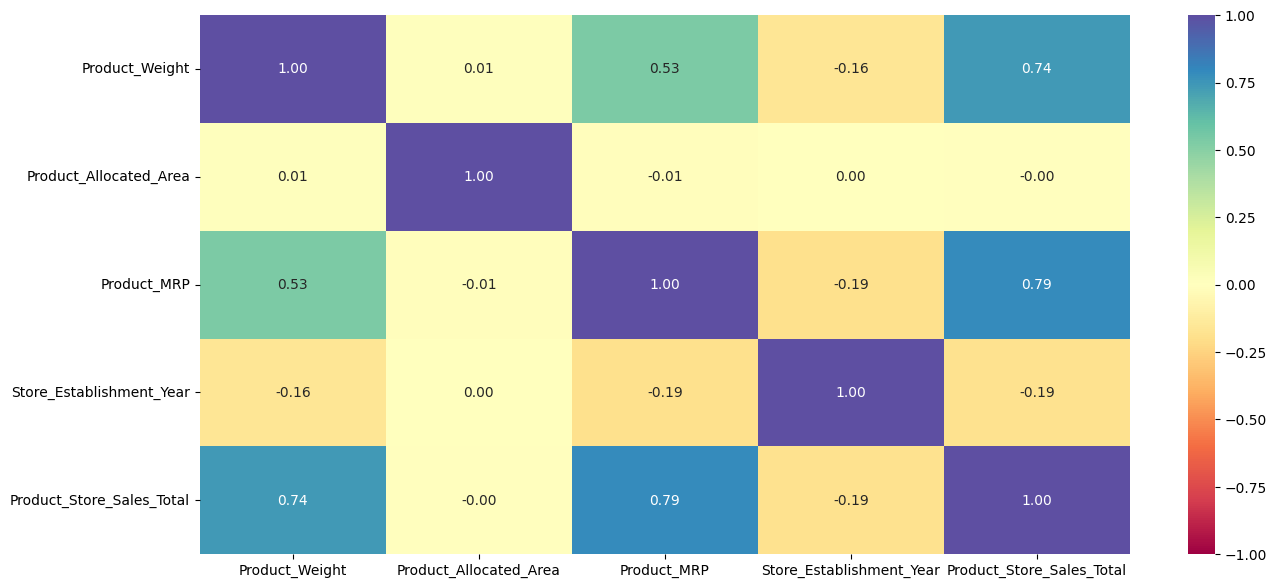

In [ ]:
# Let's check the correlation between numerical columns
plt.figure(figsize=(15, 7))
sns.heatmap(dataset.corr(numeric_only = True), annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral")
plt.show()

**Observations**

### Observations

- **Product_MRP** has strong positive correlation with sales, so higher price → higher sales.

- **Product_Weight** also has strong positive correlation with sales.

- **Product_Allocated_Area** has no impact on sales.

- **Store_Establishment_Year** has slight negative correlation with sales.

- **Product_Weight** and **Product_MRP** are moderately related.

- Most other relationships are very weak.

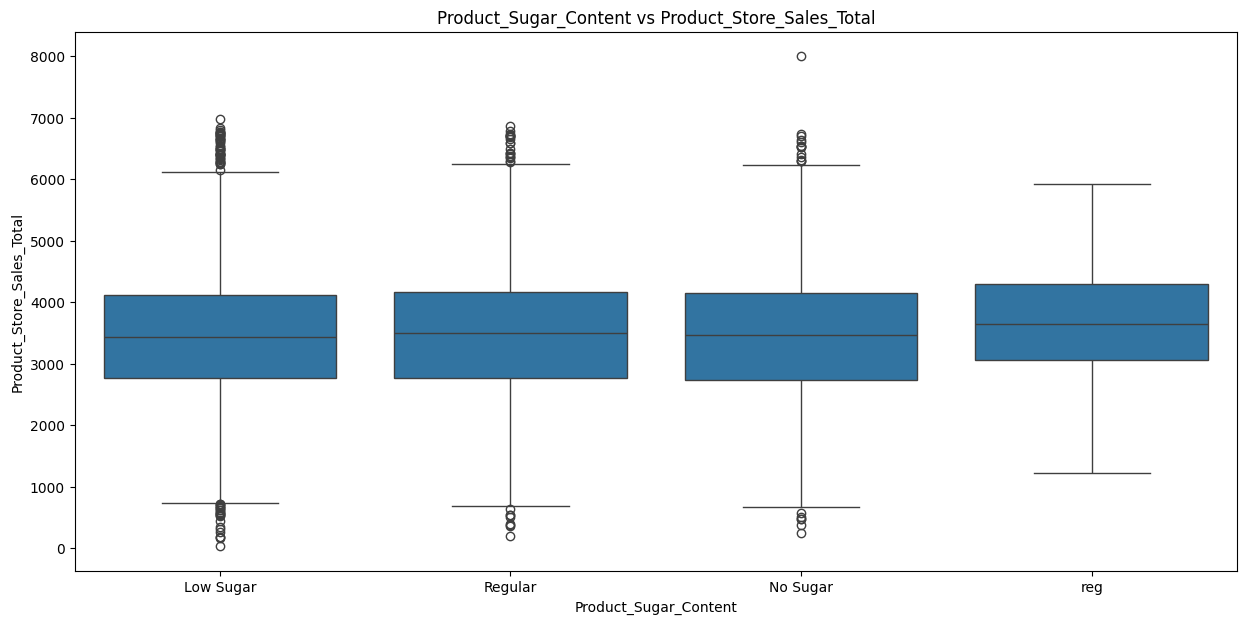

In [ ]:
# Product_Sugar_Content vs Product_Store_Sales_Total
plt.figure(figsize=(15, 7))
sns.boxplot(x="Product_Sugar_Content", y="Product_Store_Sales_Total", data=dataset)
plt.title("Product_Sugar_Content vs Product_Store_Sales_Total")
plt.show()

**Observations**

- Sales are fairly similar across sugar categories, with **'Regular' slightly higher**, and presence of outliers in all groups.

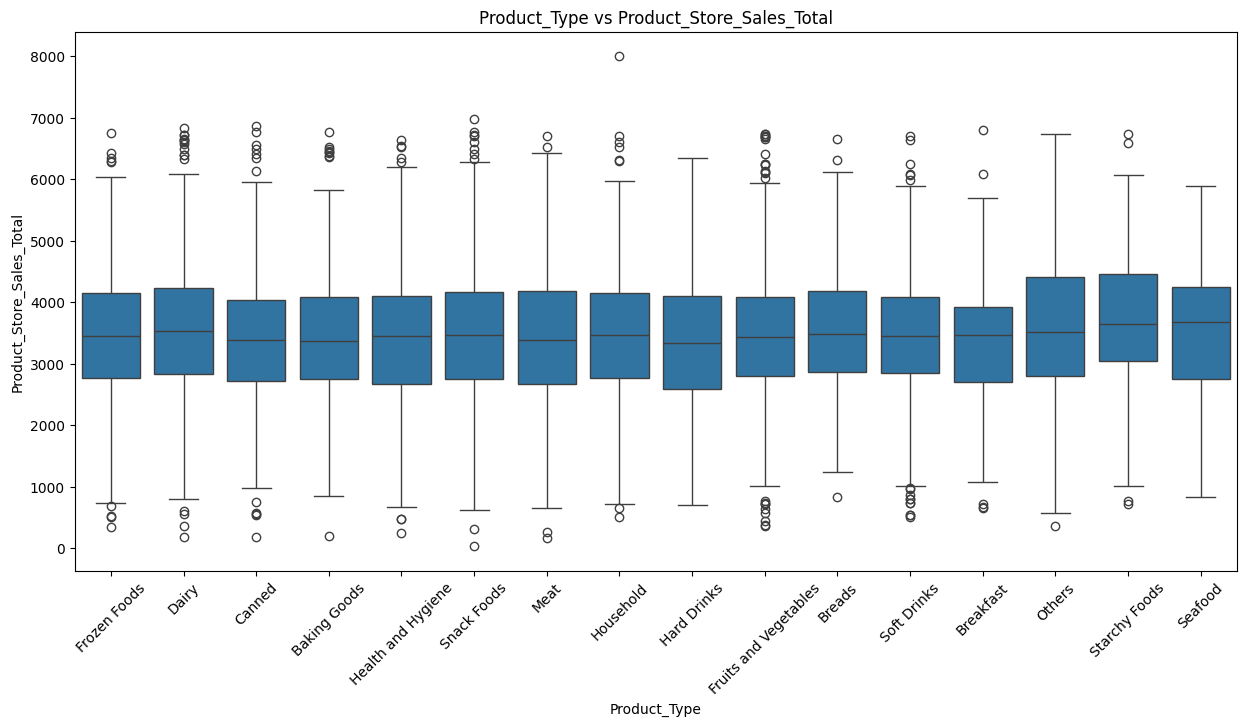

In [ ]:
# Product_Type vs Product_Store_Sales_Total
plt.figure(figsize=(15, 7))
sns.boxplot(x="Product_Type", y="Product_Store_Sales_Total", data=dataset)
plt.title("Product_Type vs Product_Store_Sales_Total")
plt.xticks(rotation=45)
plt.show()

**Observations**

- Sales are fairly consistent across product types, with slight variation where **Starchy foods and others show slightly higher median sales**, and outliers present in all categories.

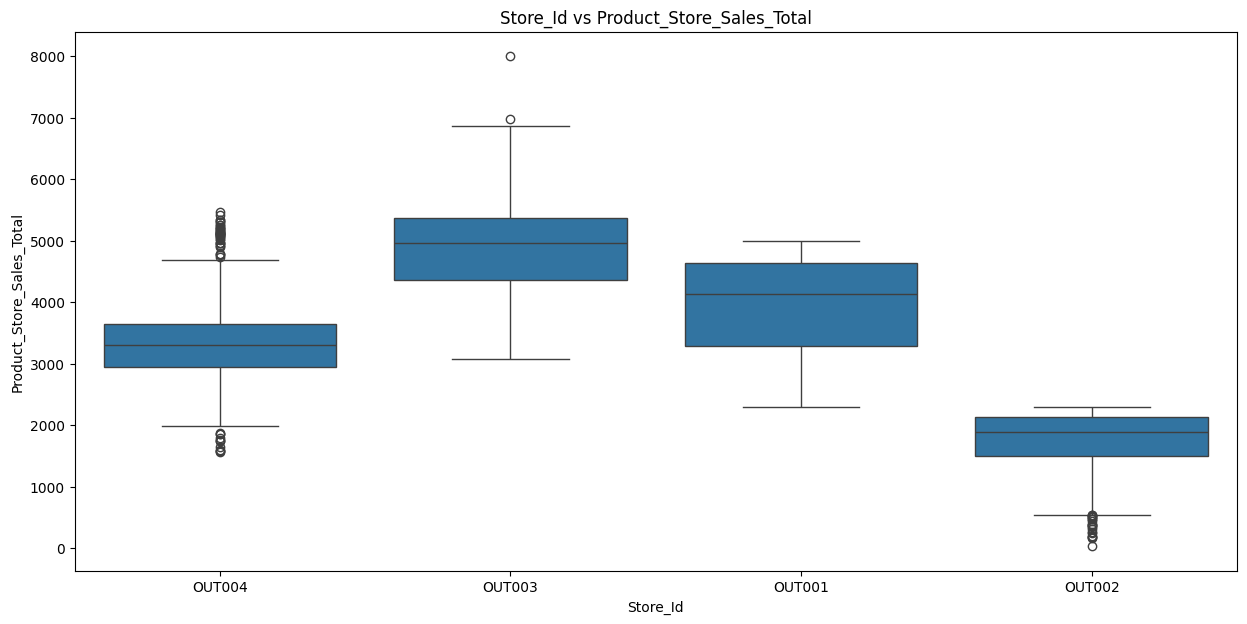

In [ ]:
# Store_Id vs Product_Store_Sales_Total
plt.figure(figsize=(15, 7))
sns.boxplot(x="Store_Id", y="Product_Store_Sales_Total", data=dataset)
plt.title("Store_Id vs Product_Store_Sales_Total")
plt.show()

**Observations**

- Sales vary significantly across stores, with **OUT003 having the highest sales**, followed by OUT001 and OUT004, while **OUT002 has the lowest sales**.

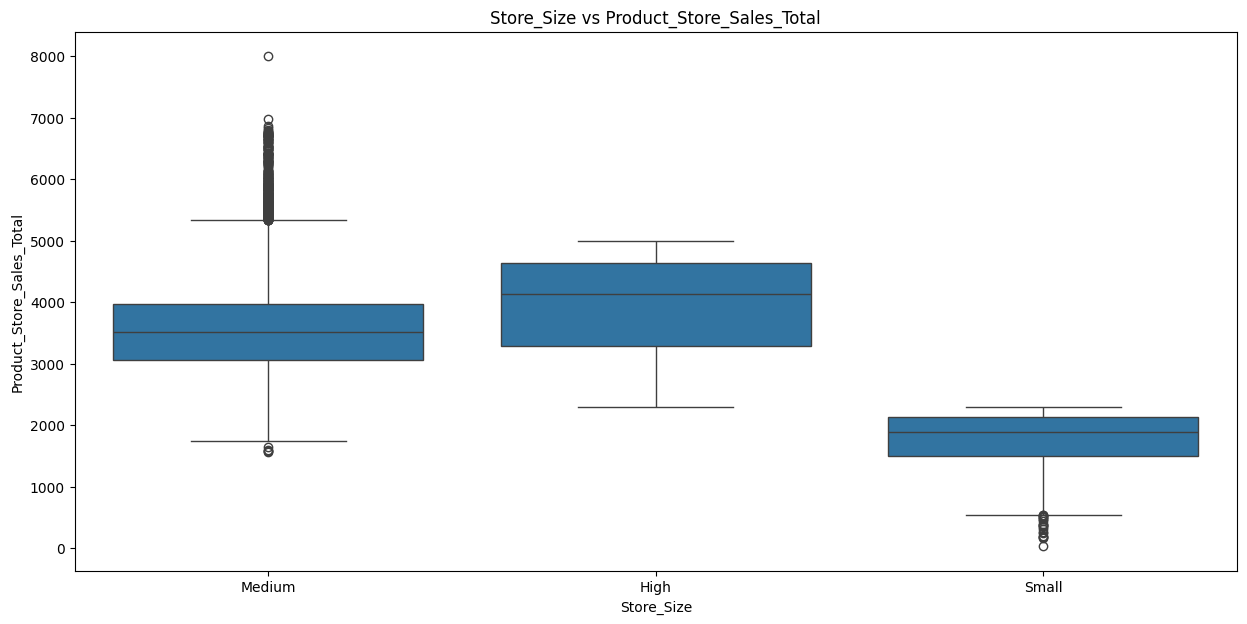

In [ ]:
# Store_Size vs Product_Store_Sales_Total
plt.figure(figsize=(15, 7))
sns.boxplot(x="Store_Size", y="Product_Store_Sales_Total", data=dataset)
plt.title("Store_Size vs Product_Store_Sales_Total")
plt.show()

**Observations**

Sales are highest in **High-size stores**, followed by medium stores, while **Small stores have the lowest sales**, with noticeable outliers in medium stores.

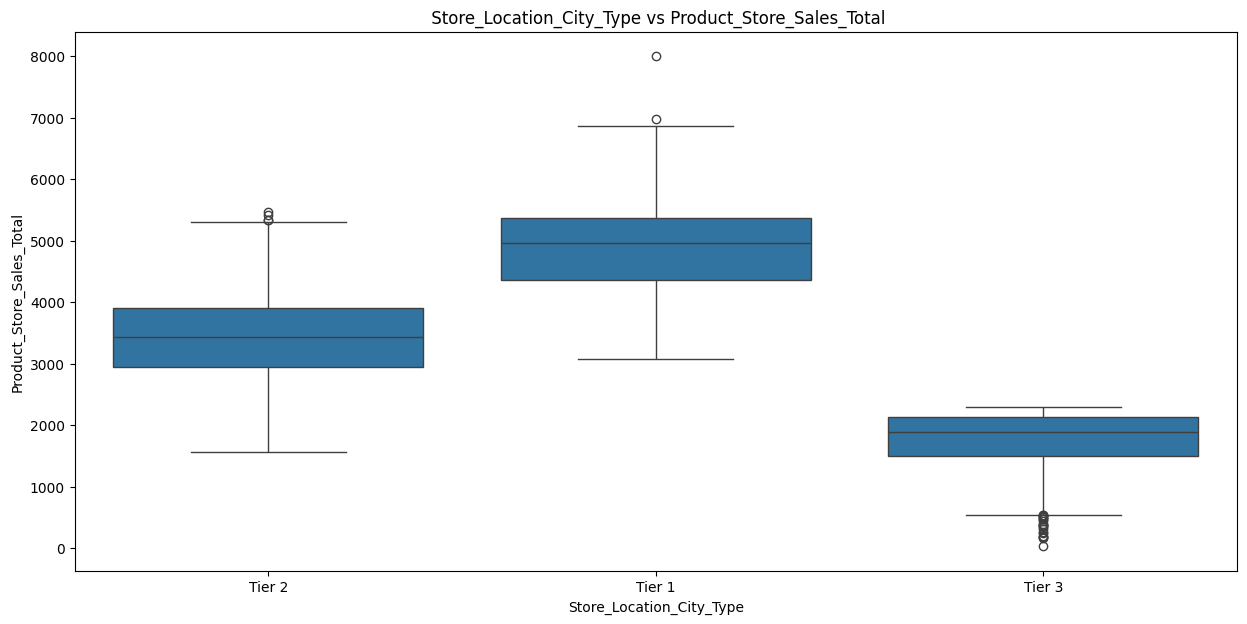

In [ ]:
# Store_Location_City_Type vs Product_Store_Sales_Total
plt.figure(figsize=(15, 7))
sns.boxplot(x="Store_Location_City_Type", y="Product_Store_Sales_Total", data=dataset)
plt.title(" Store_Location_City_Type vs Product_Store_Sales_Total")
plt.show()

**Observations**

- Sales are highest in **Tier 1 cities**, followed by Tier 2, while **Tier 3 cities have the lowest sales**, with noticeable outliers in Tier 1.

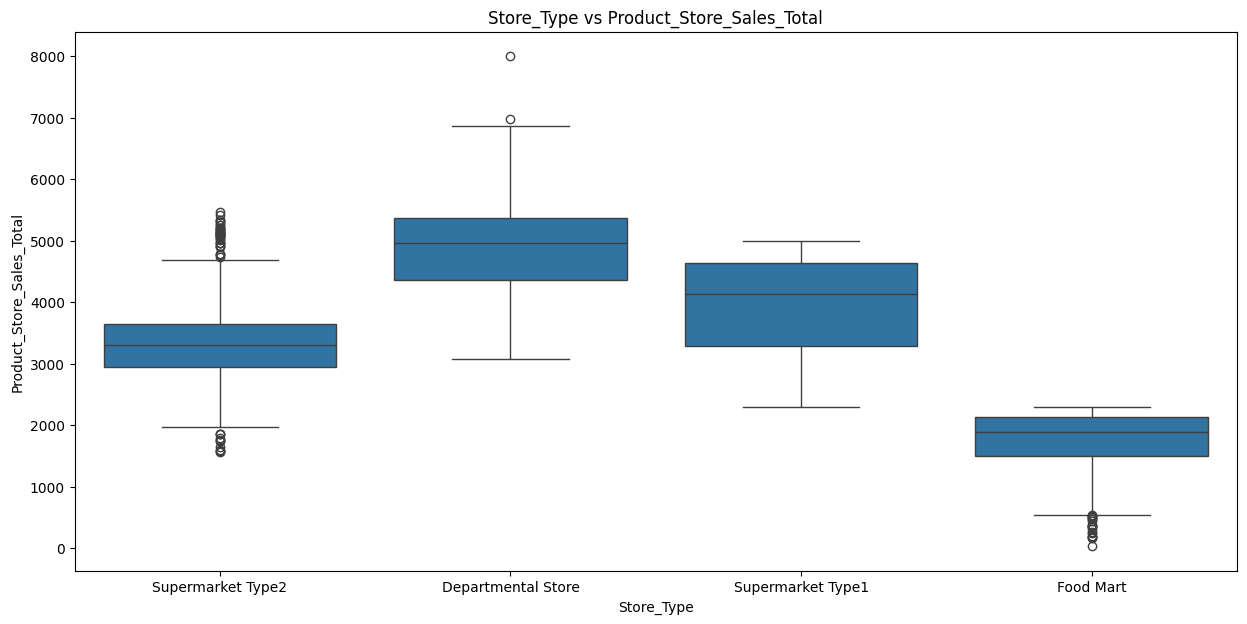

In [ ]:
# Store_Type vs Product_Store_Sales_Total
plt.figure(figsize=(15, 7))
sns.boxplot(x="Store_Type", y="Product_Store_Sales_Total", data=dataset)
plt.title("Store_Type vs Product_Store_Sales_Total")
plt.show()

**Observations**

- Sales are highest in **Departmental Stores**, followed by Supermarket Type1 and Type2, while **Food Marts have the lowest sales**, with visible outliers in all store types.

# Model Building and Hyperparameter Tuning

### Data Preprocessing Pipeline

In [9]:
# Define predictor matrix (X) using selected numeric and categorical features
X = dataset[numeric_features + categorical_features]

# Define target variable
y = dataset[target]

In [10]:
# Split the dataset into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,              # Predictors (X) and target variable (y)
    test_size=0.2,     # 20% of the data is reserved for testing
    random_state= 14  # Ensures reproducibility by setting a fixed random seed
)

In [11]:
# Create a preprocessing pipeline for numerical and categorical features

preprocessor = make_column_transformer(
    (Pipeline([('num_imputer', SimpleImputer(strategy='median')),
               ('scaler', StandardScaler())]), numeric_features),
    (Pipeline([('cat_imputer', SimpleImputer(strategy='most_frequent')),
               ('encoder', OneHotEncoder(handle_unknown='ignore'))]), categorical_features)
)

### Utility Functions

- We'll fit different models on the train data and observe their performance.
- We'll try to improve that performance by tuning some hyperparameters available for that algorithm.
- We'll use GridSearchCv for hyperparameter tuning and `r_2 score` to optimize the model.

Let's start by creating a function to get model scores, so that we don't have to use the same codes repeatedly.

In [12]:
# function to compute adjusted R-squared
def adj_r2_score(predictors, targets, predictions):
    r2 = r2_score(targets, predictions)
    n = predictors.shape[0]
    k = predictors.shape[1]
    return 1 - ((1 - r2) * (n - 1) / (n - k - 1))


# function to compute different metrics to check performance of a regression model
def model_performance_regression(model, predictors, target):
    """
    Function to compute different metrics to check regression model performance

    model: regressor
    predictors: independent variables
    target: dependent variable
    """

    # predicting using the independent variables
    pred = model.predict(predictors)

    r2 = r2_score(target, pred)  # to compute R-squared
    adjr2 = adj_r2_score(predictors, target, pred)  # to compute adjusted R-squared
    rmse = np.sqrt(mean_squared_error(target, pred))  # to compute RMSE
    mae = mean_absolute_error(target, pred)  # to compute MAE
    mape = mean_absolute_percentage_error(target, pred)  # to compute MAPE

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {
            "RMSE": rmse,
            "MAE": mae,
            "R-squared": r2,
            "Adj. R-squared": adjr2,
            "MAPE": mape,
        },
        index=[0],
    )

    return df_perf

### Random Forest Regressor - Model Training Pipeline

In [23]:
# Define base Random Forest model
rf_model = RandomForestRegressor(random_state=14)

In [24]:
# Create pipeline with preprocessing and Random Forest model
rf_pipeline = make_pipeline(preprocessor, rf_model)

In [25]:
# Train the model pipeline on the training data
rf_pipeline.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('pipeline-1',
                                                  Pipeline(steps=[('num_imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Product_Weight',
                                                   'Product_Allocated_Area',
                                                   'Product_MRP',
                                                   'Store_Establishment_Year']),
                                                 ('pipeline-2',
                                                  Pipeline(steps=[('cat_imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Product_Sugar_Content',
                                                   'Product_Type', 'Store_Id',
                                                   'Store_Size',
                                                   'Store_Location_City_Type',
                                                   'Store_Type'])])),
                ('randomforestregressor',
                 RandomForestRegressor(random_state=14))])

In [26]:
rf_estimator_model_train_perf = model_performance_regression(rf_pipeline, X_train,y_train)
print("Training performance \n")
rf_estimator_model_train_perf

Training performance 



,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,109.0746,41.661232,0.989548,0.989533,0.01561


In [27]:
rf_estimator_model_test_perf = model_performance_regression(rf_pipeline, X_test,y_test)
print("Testing performance \n")
rf_estimator_model_test_perf

Testing performance 



,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,273.552566,109.885095,0.933415,0.933033,0.037769


### Observations

The model performs **very well on training data** with very low errors and high R² (~0.99), indicating an excellent fit.

On testing data, performance drops slightly (R² ~0.93 and higher errors), but still remains strong, showing good generalization.

The gap between training and testing metrics suggests **minor overfitting**, but not severe.

Overall, the model is **reliable and accurate**, with low prediction error (low MAPE) on both datasets. Let try hyperparameter tunning to improve the model performance.

### Random Forest Regressor - Hyperparameter Tuning

In [28]:
# Choose the type of classifier.
rf_tuned = RandomForestRegressor(random_state=14)

# Create pipeline with preprocessing and XGBoost model
rf_pipeline = make_pipeline(preprocessor, rf_tuned)

# Grid of parameters to choose from
parameters = parameters = {
    'randomforestregressor__max_depth':[2, 4, 6, 8],
    'randomforestregressor__max_features': ['sqrt','log2',None],
    'randomforestregressor__n_estimators': [50, 75, 100, 125, 150]
}

# Type of scoring used to compare parameter combinations
scorer = metrics.make_scorer(metrics.r2_score)

# Run the grid search
grid_obj = GridSearchCV(rf_pipeline, parameters, scoring=scorer,cv=5)
grid_obj = grid_obj.fit(X_train, y_train)

# Set the clf to the best combination of parameters
rf_tuned = grid_obj.best_estimator_

# Fit the best algorithm to the data.
rf_tuned.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('pipeline-1',
                                                  Pipeline(steps=[('num_imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Product_Weight',
                                                   'Product_Allocated_Area',
                                                   'Product_MRP',
                                                   'Store_Establishment_Year']),
                                                 ('pipeline-2',
                                                  Pipeline(steps=[('cat_imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Product_Sugar_Content',
                                                   'Product_Type', 'Store_Id',
                                                   'Store_Size',
                                                   'Store_Location_City_Type',
                                                   'Store_Type'])])),
                ('randomforestregressor',
                 RandomForestRegressor(max_depth=8, max_features=None,
                                       n_estimators=125, random_state=14))])

In [29]:
rf_tuned_model_train_perf = model_performance_regression(rf_tuned, X_train, y_train)
print("Training performance \n")
rf_tuned_model_train_perf

Training performance 



,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,239.707202,103.260944,0.949521,0.949449,0.036268


In [30]:
rf_tuned_model_test_perf = model_performance_regression(rf_tuned, X_test, y_test)
print("Testing performance \n")
rf_tuned_model_test_perf

Testing performance 



,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,267.313793,117.741688,0.936417,0.936052,0.040987


**Observation:**

### Observations

- After tuning, training performance slightly decreased but became more realistic.

- Testing performance improved slightly, showing better generalization.

- The gap between training and testing reduced, indicating **reduced overfitting**.

Overall, the model is now more **stable and reliable**.

### XGBoost Regressor - Model Training Pipeline

In [13]:
# Define base XGBoost model
xgb_model = XGBRegressor(random_state=14)

In [14]:
# Create pipeline with preprocessing and XGBoost model
xgb_pipeline = make_pipeline(preprocessor, xgb_model)

In [15]:
# Train the model pipeline on the training data
xgb_pipeline.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('pipeline-1',
                                                  Pipeline(steps=[('num_imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Product_Weight',
                                                   'Product_Allocated_Area',
                                                   'Product_MRP',
                                                   'Store_Establishment_Year']),
                                                 ('pipeline-2',
                                                  Pipeline(steps=[('cat_imputer',
                                                                   SimpleImputer(strategy='most_frequent')),...
                              feature_types=None, gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=None,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=None, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, multi_strategy=None,
                              n_estimators=None, n_jobs=None,
                              num_parallel_tree=None, random_state=14, ...))])

In [16]:
xgb_estimator_model_train_perf = model_performance_regression(xgb_pipeline, X_train, y_train)
print("Training performance \n")
xgb_estimator_model_train_perf

Training performance 



,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,136.462594,65.871482,0.98364,0.983617,0.023152


In [17]:
xgb_estimator_model_test_perf = model_performance_regression(xgb_pipeline, X_test,y_test)
print("Testing performance \n")
xgb_estimator_model_test_perf

Testing performance 



,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,288.250327,131.249743,0.926068,0.925643,0.045648


**Observation**:

### Observations

- The XGBoost model shows **very strong performance on training data** (R² ~0.98), indicating a good fit.

- Testing performance is slightly lower (R² ~0.93) with higher errors, suggesting **some overfitting**.

- The gap between training and testing is noticeable, but overall performance is still good.

Compared to tuned models, XGBoost is **powerful but slightly less stable** in generalization.Let try hyperparameter tuning.

### XGBoost Regressor - Hyperparameter Tuning

In [18]:
# Choose the type of classifier.
xgb_tuned = XGBRegressor(random_state=14)

# Create pipeline with preprocessing and XGBoost model
xgb_pipeline = make_pipeline(preprocessor, xgb_tuned)

#Grid of parameters to choose from
param_grid = {
    'xgbregressor__n_estimators': [50, 100, 150, 200],    # number of trees to build
    'xgbregressor__max_depth': [2, 3, 4],    # maximum depth of each tree
    'xgbregressor__colsample_bytree': [0.4, 0.5, 0.6],    # percentage of attributes to be considered (randomly) for each tree
    'xgbregressor__colsample_bylevel': [0.4, 0.5, 0.6],    # percentage of attributes to be considered (randomly) for each level of a tree
    'xgbregressor__learning_rate': [0.02, 0.04, 0.1],    # learning rate
    'xgbregressor__reg_lambda': [0.4, 0.5, 0.6],    # L2 regularization factor
}

# Type of scoring used to compare parameter combinations
scorer = metrics.make_scorer(metrics.r2_score)

# Run the grid search
grid_obj = GridSearchCV(xgb_pipeline, param_grid, scoring=scorer,cv=5,n_jobs=-1)
grid_obj = grid_obj.fit(X_train, y_train)

# Set the clf to the best combination of parameters
xgb_tuned = grid_obj.best_estimator_

# Fit the best algorithm to the data.
xgb_tuned.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('pipeline-1',
                                                  Pipeline(steps=[('num_imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Product_Weight',
                                                   'Product_Allocated_Area',
                                                   'Product_MRP',
                                                   'Store_Establishment_Year']),
                                                 ('pipeline-2',
                                                  Pipeline(steps=[('cat_imputer',
                                                                   SimpleImputer(strategy='most_frequent')),...
                              feature_types=None, gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=0.1,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=4, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, multi_strategy=None,
                              n_estimators=200, n_jobs=None,
                              num_parallel_tree=None, random_state=14, ...))])

In [20]:
xgb_tuned_model_train_perf = model_performance_regression(xgb_tuned, X_train, y_train)
xgb_tuned_model_train_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,264.124924,111.619277,0.938713,0.938626,0.042613


In [21]:
xgb_tuned_model_test_perf = model_performance_regression(xgb_tuned, X_test, y_test)
print("Testing performance \n")
xgb_tuned_model_test_perf

Testing performance 



,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,282.854017,123.664845,0.92881,0.928401,0.044325


**Observation:**

- After tuning, XGBoost training performance decreased a bit but became more realistic.

- Testing performance improved slightly compared to before tuning.

- The gap between training and testing reduced, indicating **reduced overfitting**.

Overall, the tuned XGBoost model is **more stable and generalizes better**.

## Model Performance Comparison and Final Model Selection

In [31]:
# training performance comparison

models_train_comp_df = pd.concat(
    [rf_estimator_model_train_perf.T,rf_tuned_model_train_perf.T,
    xgb_estimator_model_train_perf.T,xgb_tuned_model_train_perf.T],
    axis=1,
)

models_train_comp_df.columns = [
    "Random Forest Estimator",
    "Random Forest Tuned",
    "XGBoost",
    "XGBoost Tuned"
]

print("Training performance comparison:")
models_train_comp_df

Training performance comparison:


,Random Forest Estimator,Random Forest Tuned,XGBoost,XGBoost Tuned
RMSE,109.074600,239.707202,136.462594,264.124924
MAE,41.661232,103.260944,65.871482,111.619277
R-squared,0.989548,0.949521,0.983640,0.938713
Adj. R-squared,0.989533,0.949449,0.983617,0.938626
MAPE,0.015610,0.036268,0.023152,0.042613


In [32]:
# Testing performance comparison

models_test_comp_df = pd.concat(
    [rf_estimator_model_test_perf.T,rf_tuned_model_test_perf.T,
    xgb_estimator_model_test_perf.T,xgb_tuned_model_test_perf.T],
    axis=1,
)

models_test_comp_df.columns = [
    "Random Forest Estimator",
    "Random Forest Tuned",
    "XGBoost",
    "XGBoost Tuned"
]

print("Testing performance comparison:")
models_test_comp_df

Testing performance comparison:


,Random Forest Estimator,Random Forest Tuned,XGBoost,XGBoost Tuned
RMSE,273.552566,267.313793,288.250327,282.854017
MAE,109.885095,117.741688,131.249743,123.664845
R-squared,0.933415,0.936417,0.926068,0.928810
Adj. R-squared,0.933033,0.936052,0.925643,0.928401
MAPE,0.037769,0.040987,0.045648,0.044325


In [33]:
(models_train_comp_df - models_test_comp_df).iloc[2]

,R-squared
Random Forest Estimator,0.056133
Random Forest Tuned,0.013104
XGBoost,0.057573
XGBoost Tuned,0.009903


**Observations:**

### Observations

- All models show a **very small difference in R² between training and testing**, indicating good generalization.

- Untuned Random Forest and XGBoost have slightly higher gaps, suggesting **minor overfitting**.

- Tuned models have **lower gaps**, indicating they are more stable and less overfitted.

XGBoost Tuned is the best choice. It has **strong test performance (R² ~0.93)**, which is what actually matters. It shows a **smaller gap between training and testing**, meaning less overfitting. Errors (RMSE, MAE, MAPE) are **reasonably low and consistent**, making predictions reliable

# Model Serialization

Note: Based on the model comparison, the XGB-tuned model demonstrated the best performance on the testing data. Therefore, we will serialize this model for deployment.

In [ ]:
# Create a folder for storing the files needed for web app deployment
os.makedirs("deployment_files", exist_ok=True)

In [ ]:
# Define the file path to save (serialize) the trained model along with the data preprocessing steps
saved_model_path = "deployment_files/sales_prediction_superkart_v1_0.joblib"

In [ ]:
# Save the best trained model pipeline using joblib
joblib.dump(xgb_tuned, saved_model_path)

print(f"Model saved successfully at {saved_model_path}")

Model saved successfully at deployment_files/sales_prediction_superkart_v1_0.joblib


In [ ]:
# Load the saved model pipeline from the file
saved_model = joblib.load("deployment_files/sales_prediction_superkart_v1_0.joblib")

# Confirm the model is loaded
print("Model loaded successfully.")

Model loaded successfully.


In [ ]:
saved_model

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('pipeline-1',
                                                  Pipeline(steps=[('num_imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['accommodates', 'bathrooms',
                                                   'review_scores_rating',
                                                   'bedrooms', 'beds']),
                                                 ('pipeline-2',
                                                  Pipeline(steps=[('cat_imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneH...
                              device=None, early_stopping_rounds=None,
                              enable_categorical=False, eval_metric=None,
                              feature_types=None, gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=None,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=None, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, ...))])

Let's try making predictions on the test set using the deserialized model.

- Please ensure that the saved model is loaded before making predictions.

In [ ]:
saved_model.predict(X_test)

array([3131.9858, 3403.8564, 3059.3389, ..., 3807.8787, 2615.8445,
       2842.3894], dtype=float32)

- As we can see, the model can be directly used for making predictions without any retraining.

# Deployment Back End

## Load the Serialized Model


In [ ]:
import os

# Create a folder to upload your trained serialized model into it
os.makedirs("backend_files", exist_ok=True)

In [ ]:
# Define the file path to load the uploaded serialized model
model_path = "backend_files/sales_prediction_superkart_v1_0.joblib"

In [ ]:
import joblib

# Load the saved model pipeline from the file
saved_model = joblib.load(model_path)

# Confirm the model is loaded
print("Model loaded successfully.")

Model loaded successfully.


## App Backend

## Setting up a Hugging Face Docker Space for the Backend

In [ ]:
import os # Import the login function from the huggingface_hub library
from huggingface_hub import login

# Login to your Hugging Face account using your access token
# Token removed for privacy
login(token="YOUR_HF_TOKEN")

# Import the create_repo function from the huggingface_hub library
from huggingface_hub import create_repo

In [ ]:
# Try to create the repository for the Hugging Face Space
try:
    create_repo("SuperKartSalesPrediction-Backend",  # One can replace "Backend_Docker_space" with the desired space name
        repo_type="space",  # Specify the repository type as "space"
        space_sdk="docker",  # Specify the space SDK as "docker" to create a Docker space
        private=False  # Set to True if you want the space to be private
    )
except Exception as e:
    # Handle potential errors during repository creation
    if "RepositoryAlreadyExistsError" in str(e):
        print("Repository already exists. Skipping creation.")
    else:
        print(f"Error creating repository: {e}")

Error creating repository: Client error '409 Conflict' for url 'https://huggingface.co/api/repos/create' (Request ID: Root=1-69f72b29-2e07029f3e4f5389490d43df;59c87a4c-956e-47ff-a044-10e90848ee56)
For more information check: https://developer.mozilla.org/en-US/docs/Web/HTTP/Status/409

You already created this space repo: saikrishnachavva/SuperKartSalesPrediction


## Flask Web Framework


In [ ]:
%%writefile backend_files/app.py

# Import necessary libraries
import numpy as np
import joblib
import pandas as pd
from flask import Flask, request, jsonify

# Initialize Flask app
superkart_sales_api = Flask("SuperKart Sales Prediction API")

# Load trained model
model = joblib.load("sales_prediction_superkart_v1_0.joblib")

# Home route
@superkart_sales_api.get('/')
def home():
    return "Welcome to the SuperKart Sales Prediction API!"

# 🔹 Single prediction endpoint
@superkart_sales_api.post('/v1/predict')
def predict_sales():
    data = request.get_json()

    # Map input features (must match training columns)
    sample = {
        'Product_Weight': data['Product_Weight'],
        'Product_Sugar_Content': data['Product_Sugar_Content'],
        'Product_Allocated_Area': data['Product_Allocated_Area'],
        'Product_Type': data['Product_Type'],
        'Product_MRP': data['Product_MRP'],
        'Store_Id': data['Store_Id'],
        'Store_Establishment_Year': data['Store_Establishment_Year'],
        'Store_Size': data['Store_Size'],
        'Store_Location_City_Type': data['Store_Location_City_Type'],
        'Store_Type': data['Store_Type']
    }

    input_df = pd.DataFrame([sample])

    # Predict sales
    predicted_sales = model.predict(input_df)[0]

    # Convert to float
    predicted_sales = round(float(predicted_sales), 2)

    return jsonify({
        'Predicted_Product_Store_Sales_Total': predicted_sales
    })


# 🔹 Batch prediction endpoint
@superkart_sales_api.post('/v1/predict_batch')
def predict_sales_batch():
    file = request.files['file']

    input_df = pd.read_csv(file)

    predictions = model.predict(input_df).tolist()

    predictions = [round(float(p), 2) for p in predictions]

    # Optional: attach with Product_Id
    if 'Product_Id' in input_df.columns:
        output = dict(zip(input_df['Product_Id'], predictions))
    else:
        output = {"predictions": predictions}

    return output


# Run app
if __name__ == '__main__':
    superkart_sales_api.run(debug=True)

Overwriting backend_files/app.py


## Dependencies File


In [ ]:
%%writefile backend_files/requirements.txt
pandas==2.2.2
numpy==2.0.2
scikit-learn==1.6.1
xgboost==2.1.4
joblib==1.4.2
Werkzeug==2.2.2
flask==2.2.2
gunicorn==20.1.0
requests==2.28.1
uvicorn[standard]
streamlit==1.43.2

Writing backend_files/requirements.txt


## Docker File

In [ ]:
%%writefile backend_files/Dockerfile
FROM python:3.9-slim

# Set the working directory inside the container
WORKDIR /app

# Copy all files from the current directory to the container's working directory
COPY . .

# Install dependencies from the requirements file without using cache to reduce image size
RUN pip install --no-cache-dir --upgrade -r requirements.txt

# Define the command to start the application using Gunicorn with 4 worker processes
# - `-w 4`: Uses 4 worker processes for handling requests
# - `-b 0.0.0.0:7860`: Binds the server to port 7860 on all network interfaces
# - `app:app`: Runs the Flask app (assuming `app.py` contains the Flask instance named `app`)
CMD ["gunicorn", "-w", "4", "-b", "0.0.0.0:7860", "app:superkart_sales_api"]

Writing backend_files/Dockerfile


## Uploading Files to Hugging Face Space for the Backend

In [ ]:
# for hugging face space authentication to upload files
from huggingface_hub import HfApi

repo_id = "saikrishnachavva/SuperKartSalesPrediction-Backend"  # Your Hugging Face space id

# Initialize the API
api = HfApi()

# Upload Streamlit app files stored in the folder called deployment_files
api.upload_folder(
    folder_path="/content/backend_files",  # Local folder path
    repo_id=repo_id,  # Hugging face space id
    repo_type="space",  # Hugging face repo type "space"
)

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...ion_superkart_v1_0.joblib: 100%|##########|  209kB /  209kB            

CommitInfo(commit_url='https://huggingface.co/spaces/saikrishnachavva/SuperKartSalesPrediction/commit/76ab03011545cc0fa3907e060e215fd051410442', commit_message='Upload folder using huggingface_hub', commit_description='', oid='76ab03011545cc0fa3907e060e215fd051410442', pr_url=None, repo_url=RepoUrl('https://huggingface.co/spaces/saikrishnachavva/SuperKartSalesPrediction', endpoint='https://huggingface.co', repo_type='space', repo_id='saikrishnachavva/SuperKartSalesPrediction'), pr_revision=None, pr_num=None)

## Hugging Face Link (Backend) :-
https://huggingface.co/spaces/saikrishnachavva/SuperKartSalesPrediction-Backend

# Deployment Front End

## Setting up a Hugging Face Docker Streamlit Space for the Frontend

Points to note before executing the below cells
- Create a Streamlit space on Hugging Face by following the instructions provided on the content page titled Creating Spaces and Adding Secrets in Hugging Face from Week 1

In [ ]:
# Try to create the repository for the Hugging Face Space
try:
    create_repo("SuperKartSalesPrediction-Frontend",  # One can replace "Backend_Docker_space" with the desired space name
        repo_type="space",  # Specify the repository type as "space"
        space_sdk="docker",  # Specify the space SDK as "docker" to create a Docker space
        private=False  # Set to True if you want the space to be private
    )
except Exception as e:
    # Handle potential errors during repository creation
    if "RepositoryAlreadyExistsError" in str(e):
        print("Repository already exists. Skipping creation.")
    else:
        print(f"Error creating repository: {e}")

In [ ]:
# Create a folder for storing the files needed for frontend UI deployment
os.makedirs("frontend_files", exist_ok=True)

In [ ]:
%%writefile frontend_files/app.py

import streamlit as st
import requests

st.title("SuperKart Sales Prediction")

# -----------------------------
#  PREDICTION
# -----------------------------
st.subheader("Online Prediction")

# Product features
product_weight = st.number_input("Product Weight", min_value=0.0, value=5.0)

product_sugar_content = st.selectbox(
    "Product Sugar Content",
    ["Low Sugar", "Regular", "No Sugar","reg"]  #
)

product_allocated_area = st.number_input(
    "Product Allocated Area", min_value=0.0, max_value=1.0, value=0.05
)

product_type = st.selectbox(
    "Product Type",
    [
        "Fruits and Vegetables", "Snack Foods", "Frozen Foods", "Dairy",
        "Household", "Baking Goods", "Canned", "Health and Hygiene",
        "Meat", "Soft Drinks", "Breads", "Hard Drinks",
        "Others", "Starchy Foods", "Breakfast", "Seafood"
    ]
)

product_mrp = st.number_input("Product MRP", min_value=0.0, value=100.0)

# Store features
store_id = st.selectbox(
    "Store ID",
    ["OUT004", "OUT001", "OUT003", "OUT002"]
)

store_est_year = st.number_input(
    "Store Establishment Year", min_value=1900, value=2005
)

store_size = st.selectbox(
    "Store Size",
    ["Medium", "High", "Small"]  #
)

store_city_type = st.selectbox(
    "Store Location City Type",
    ["Tier 2", "Tier 1", "Tier 3"]  #
)

store_type = st.selectbox(
    "Store Type",
    [
        "Supermarket Type2",
        "Supermarket Type1",
        "Departmental Store",
        "Food Mart"
    ]
)

# Input payload
input_data = {
    "Product_Weight": product_weight,
    "Product_Sugar_Content": product_sugar_content,
    "Product_Allocated_Area": product_allocated_area,
    "Product_Type": product_type,
    "Product_MRP": product_mrp,
    "Store_Id": store_id,
    "Store_Establishment_Year": store_est_year,
    "Store_Size": store_size,
    "Store_Location_City_Type": store_city_type,
    "Store_Type": store_type
}

# Prediction
if st.button("Predict Sales"):
    response = requests.post(
        "https://saikrishnachavva-SuperKartSalesPrediction-Backend.hf.space/v1/predict",
        json=input_data
    )

    if response.status_code == 200:
        prediction = response.json()['Predicted_Product_Store_Sales_Total']
        st.success(f"Predicted Sales: ₹ {prediction}")
    else:
        st.error("Error making prediction.")


# -----------------------------
# 🔹 BATCH PREDICTION
# -----------------------------
st.subheader("Batch Prediction")

uploaded_file = st.file_uploader("Upload CSV file", type=["csv"])

if uploaded_file is not None:
    if st.button("Predict Batch"):
        response = requests.post(
            "https://saikrishnachavva-SuperKartSalesPrediction-Backend.hf.space/v1/predict_batch",
            files={"file": uploaded_file}
        )

        if response.status_code == 200:
            st.success("Batch predictions completed!")
            st.write(response.json())
        else:
            st.error("Error making batch prediction.")

Overwriting frontend_files/app.py


## Dependencies File

In [ ]:
%%writefile frontend_files/requirements.txt
pandas==2.2.2
requests==2.28.1
streamlit==1.43.2

Writing frontend_files/requirements.txt


## Dockerfile

In [ ]:
%%writefile frontend_files/Dockerfile
# Use a minimal base image with Python 3.9 installed
FROM python:3.9-slim

# Set the working directory inside the container to /app
WORKDIR /app

# Copy all files from the current directory on the host to the container's /app directory
COPY . .

# Install Python dependencies listed in requirements.txt
RUN pip3 install -r requirements.txt

# Define the command to run the Streamlit app on port 8501 and make it accessible externally
CMD ["streamlit", "run", "app.py", "--server.port=7860", "--server.address=0.0.0.0", "--server.enableXsrfProtection=false"]

# NOTE: Disable XSRF protection for easier external access in order to make batch predictions

Overwriting frontend_files/Dockerfile


In [ ]:
# Create inside frontend_files
os.makedirs("frontend_files/.streamlit", exist_ok=True)

with open("frontend_files/.streamlit/config.toml", "w") as f:
    f.write("""
[server]
port = 7860
address = "0.0.0.0"
""")

## Uploading Files to Hugging Face Space for the Frontend

In [ ]:
# for hugging face space authentication to upload files
from huggingface_hub import HfApi

repo_id = "saikrishnachavva/SuperKartSalesPrediction-Frontend"

# Initialize the API
api = HfApi()

# Upload Streamlit app files stored in the folder called deployment_files
api.upload_folder(
    folder_path="/content/frontend_files",  # Local folder path
    repo_id=repo_id,  # Hugging face space id
    repo_type="space",  # Hugging face repo type "space"
)

CommitInfo(commit_url='https://huggingface.co/spaces/saikrishnachavva/SuperKartSalesPrediction/commit/5491ea70b78c78a8efda691dcb7c7d67d5c00d7e', commit_message='Upload folder using huggingface_hub', commit_description='', oid='5491ea70b78c78a8efda691dcb7c7d67d5c00d7e', pr_url=None, repo_url=RepoUrl('https://huggingface.co/spaces/saikrishnachavva/SuperKartSalesPrediction', endpoint='https://huggingface.co', repo_type='space', repo_id='saikrishnachavva/SuperKartSalesPrediction'), pr_revision=None, pr_num=None)

## Hugging Face Link (Frontend) :-
https://huggingface.co/spaces/saikrishnachavva/SuperKartSalesPrediction-Frontend

# Actionable Insights and Recommendations


## Key Insights from Analysis

### 1. Store Type Influence on Sales
- Supermarket Type2 stores dominate (~53%) and larger formats generate higher sales due to better visibility and assortment.

### 2. Tier 2 Cities as Revenue Drivers
- Tier 2 cities contribute ~71% of the data and act as the primary revenue drivers.

### 3. Product Category Performance
- Fruits and Vegetables, Snack Foods, and Dairy perform well while Seafood and Breakfast contribute less.

### 4. Data Quality Issues
- Product_Sugar_Content has inconsistent values like "Regular" and "reg" which can affect model accuracy.

### 5. Store Size Distribution
- Medium stores (~68%) dominate while high-sized stores show higher sales potential.

## Business Recommendations

### 1. Focus Expansion in Tier 2 Cities
- Increase store presence and customize inventory in Tier 2 regions to maximize growth.

### 2. Optimize Product Mix
- Prioritize high-performing categories and reduce focus on low-demand categories.

### 3. Upgrade High-Potential Stores
- Convert high-performing medium stores into larger formats to increase revenue.

### 4. Data-Driven Inventory Management
- Use the prediction model to forecast demand and reduce stockouts and overstock.

### 5. Improve Data Quality
- Standardize inconsistent categories and implement validation pipelines.

## Deployment and System Insights

### 1. Scalability and Flexibility
- Separate frontend and backend enables independent scaling and easier updates.

### 2. API Reusability
- Backend API can be reused across dashboards, apps, and external systems.

### 3. Technology Agnostic Design
- Different technologies can be used for frontend and backend for flexibility.

### 4. Real-Time Prediction Capability
- System allows instant prediction of sales based on input features.

### 5. Continuous Improvement
- Model can be retrained and updated without impacting the frontend.

## Conclusion
- The solution enables accurate product-store level sales prediction and supports better decision-making through a scalable and production-ready system.